

# 0.1 Environment (Google Colab or local Jupyter)
# REF: Week1_Day02_PySpark_Student_Workbook › Sub-task 0.1 (cell-1)



In [ ]:
import sys, os, time, json, math

IN_COLAB = 'google.colab' in sys.modules              # EXPLAIN: True only when running on Google Colab
if IN_COLAB:
    !apt-get -qq install -y openjdk-17-jdk-headless > /dev/null
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    ## AI: added huggingface_hub (dataset download) and matplotlib (Fig. T1.1)
    !pip install -q pyspark huggingface_hub matplotlib
else:
    try:
        import pyspark; print("Local PySpark", pyspark.__version__)
    except ImportError:
        !pip install pyspark huggingface_hub matplotlib

0.2 Download climate.csv from Hugging Face

In [ ]:

# REF: Day02_LiveCoding_Colab › Block 0 (cell-5) downloaded with the Kaggle CLI.
DATA_DIR = os.environ.get("CW_DATA_DIR", "/content/data" if IN_COLAB else "./data")
CSV_PATH = os.path.join(DATA_DIR, "climate.csv")
os.makedirs(DATA_DIR, exist_ok=True)                   # EXPLAIN: create the folder if missing

if not os.path.exists(CSV_PATH):                       # EXPLAIN: skip the 2.73 GB download if already present
    from huggingface_hub import hf_hub_download        # EXPLAIN: downloads one file from a Hugging Face repo
    hf_hub_download(repo_id="CatLikeIceCream/temperature", filename="climate.csv",
                    repo_type="dataset", local_dir=DATA_DIR)
print("Data file:", CSV_PATH, "| exists:", os.path.exists(CSV_PATH))

Data file: /content/data/climate.csv | exists: True


1. Student Name and Dataset declaration

In [ ]:
DECLARATION = {
    "student_name"   : "<<YOUR FULL NAME>>",
    "student_email"  : "<<YOUR UNIVERSITY E-MAIL>>",
    "sid"            : "<<YOUR SID>>",
    "pool_reference" : "<<POOL REF>>",
    "dataset_name"   : "climate.csv - GHCN-Daily US weather-station records (1970-2023)",
    "source_url"     : "https://huggingface.co/datasets/CatLikeIceCream/temperature",
    "original_source": "NOAA NCEI Global Historical Climatology Network - Daily (GHCN-Daily)",
    "licence"        : "None declared on the Hugging Face mirror; original NOAA GHCN-Daily is US-Government "
                       "public-domain data (citation of Menne et al. 2012 requested)",
    "problem"        : "REGRESSION - predict next-day maximum temperature (deg C) per station",
}
for k, v in DECLARATION.items():
    print(f"{k:16s}: {v}")

student_name    : <<YOUR FULL NAME>>
student_email   : <<YOUR UNIVERSITY E-MAIL>>
sid             : <<YOUR SID>>
pool_reference  : <<POOL REF>>
dataset_name    : climate.csv - GHCN-Daily US weather-station records (1970-2023)
source_url      : https://huggingface.co/datasets/CatLikeIceCream/temperature
original_source : NOAA NCEI Global Historical Climatology Network - Daily (GHCN-Daily)
licence         : None declared on the Hugging Face mirror; original NOAA GHCN-Daily is US-Government public-domain data (citation of Menne et al. 2012 requested)
problem         : REGRESSION - predict next-day maximum temperature (deg C) per station


# 2. SparkSession initialisation and cluster configuration
# REF: Week1_Day02_PySpark_Student_Workbook › Exercise 0, Sub-tasks 0.1–0.2 (cell-5)
##      Changed: shuffle partitions 8 -> 32 and driver memory 4g -> 6g for a 2.73 GB file



In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import types as T
from pyspark.sql.window import Window

DRIVER_MEMORY      = os.environ.get("CW_DRIVER_MEMORY", "6g")
SHUFFLE_PARTITIONS = int(os.environ.get("CW_SHUFFLE_PARTITIONS", "32"))

spark = (SparkSession.builder                                   # EXPLAIN: builder collects settings before start-up
         .appName("7006SCN-Task1-GHCN-Regression")              # EXPLAIN: name shown in the Spark UI
         .master("local[*]")                                    # EXPLAIN: run on all local CPU cores
         .config("spark.driver.memory", DRIVER_MEMORY)          # EXPLAIN: JVM memory
         .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTITIONS))  # EXPLAIN: partitions after a shuffle
         .config("spark.sql.ansi.enabled", "true")              # EXPLAIN: strict type checking
         .config("spark.ui.showConsoleProgress", "false")       # EXPLAIN: hide progress bars in outputs
         .getOrCreate())                                        # EXPLAIN: start Spark (or reuse a running session)
spark.sparkContext.setLogLevel("ERROR")                         # EXPLAIN: only show errors in the log

CLUSTER_CONFIG = {
    "spark_version": spark.version,
    "master": spark.sparkContext.master,
    "default_parallelism": spark.sparkContext.defaultParallelism,   # EXPLAIN: number of parallel task slots
    "driver_memory": DRIVER_MEMORY,
    "shuffle_partitions": SHUFFLE_PARTITIONS,
    "ansi_enabled": spark.conf.get("spark.sql.ansi.enabled"),
}
for k, v in CLUSTER_CONFIG.items():
    print(f"{k:20s}: {v}")
TIMINGS = {}

spark_version       : 4.0.4
master              : local[*]
default_parallelism : 2
driver_memory       : 6g
shuffle_partitions  : 32
ansi_enabled        : true


3. dataset  loading

In [ ]:
DAY_COLS = [f"DAY{i}" for i in range(1, 32)]

RAW_SCHEMA = T.StructType(                                       # EXPLAIN: StructType = list of columns
    [T.StructField("ID", T.StringType(), True),                  # EXPLAIN: StructField(name, type, nullable)
     T.StructField("YEAR", T.IntegerType(), True),
     T.StructField("MONTH", T.IntegerType(), True),
     T.StructField("ELEM", T.StringType(), True)]
    + [T.StructField(d, T.DoubleType(), True) for d in DAY_COLS])

raw = (spark.read
       .option("header", "true")                                 # EXPLAIN: first line holds the column names
       .option("mode", "PERMISSIVE")                             # EXPLAIN: bad values become NULL instead of failing
       .schema(RAW_SCHEMA)                                       # EXPLAIN: use the declared types
       .csv(CSV_PATH))                                           # EXPLAIN: lazy; nothing is read until an action runs
raw.show(6, truncate=True)                                       # EXPLAIN: print the first 6 rows

+-----------+----+-----+----+----+-----+-----+-----+-----+-----+------+------+------+------+------+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+
|         ID|YEAR|MONTH|ELEM|DAY1| DAY2| DAY3| DAY4| DAY5| DAY6|  DAY7|  DAY8|  DAY9| DAY10| DAY11|DAY12|DAY13|DAY14|DAY15|DAY16|DAY17|DAY18|DAY19|DAY20|DAY21|DAY22|DAY23|DAY24|DAY25|DAY26|DAY27|DAY28|DAY29|DAY30|DAY31|
+-----------+----+-----+----+----+-----+-----+-----+-----+-----+------+------+------+------+------+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+
|USC00010160|1970|    1|TMAX|39.0| 72.0|122.0| 61.0|106.0|100.0|  44.0| -39.0| -22.0| -11.0|  39.0| 44.0| 61.0|122.0|150.0|128.0|156.0|100.0|117.0| 28.0| 17.0| 11.0| 39.0| 33.0|150.0|178.0|228.0|228.0|222.0|189.0| 89.0|
|USC00010160|1970|    1|TMIN|11.0|-61.0|-39.0|-67.0|-50.0| -6.0|-111.0|-122.0|-150.0|-122.0|-111.0|  0.0|-33.0|-67.0|-39

4.SCHEMA INSPECTION

In [ ]:
 # REF: Week1_Day02_PySpark_Student_Workbook › Exercise 2, Sub-task 2.1 (cell-9): df.columns
# ==============================================================================
raw.printSchema()                                                # EXPLAIN: prints every column name and type
print("Element codes (ELEM):", [r["ELEM"] for r in raw.select("ELEM").distinct().orderBy("ELEM").collect()])

root
 |-- ID: string (nullable = true)
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- ELEM: string (nullable = true)
 |-- DAY1: double (nullable = true)
 |-- DAY2: double (nullable = true)
 |-- DAY3: double (nullable = true)
 |-- DAY4: double (nullable = true)
 |-- DAY5: double (nullable = true)
 |-- DAY6: double (nullable = true)
 |-- DAY7: double (nullable = true)
 |-- DAY8: double (nullable = true)
 |-- DAY9: double (nullable = true)
 |-- DAY10: double (nullable = true)
 |-- DAY11: double (nullable = true)
 |-- DAY12: double (nullable = true)
 |-- DAY13: double (nullable = true)
 |-- DAY14: double (nullable = true)
 |-- DAY15: double (nullable = true)
 |-- DAY16: double (nullable = true)
 |-- DAY17: double (nullable = true)
 |-- DAY18: double (nullable = true)
 |-- DAY19: double (nullable = true)
 |-- DAY20: double (nullable = true)
 |-- DAY21: double (nullable = true)
 |-- DAY22: double (nullable = true)
 |-- DAY23: double (nullable = true)
 |-- DAY

5. ROW AND COLUMN COUNT

In [ ]:
# REF: Day02_LiveCoding › Block 0 activity (cell-6): rows = df.count(); len(df.columns
t0 = time.time()
N_ROWS = raw.count()                                             # EXPLAIN: ACTION - reads the whole file and counts rows
TIMINGS["full_scan_count_s"] = round(time.time() - t0, 2)        # EXPLAIN: time.time() = current time in seconds
N_COLS = len(raw.columns)                                        # EXPLAIN: raw.columns is the list of column names

print(f"rows    = {N_ROWS:,}")
print(f"columns = {N_COLS}")
print(f"full scan took {TIMINGS['full_scan_count_s']} s  ({N_ROWS / max(TIMINGS['full_scan_count_s'], 1e-6):,.0f} rows/s)")
print("Big Data requirement >= 10 million rows:", N_ROWS >= 10_000_000, "| >= 10 columns:", N_COLS >= 10)

rows    = 17,097,453
columns = 35
full scan took 9.72 s  (1,758,997 rows/s)
Big Data requirement >= 10 million rows: True | >= 10 columns: True


6. FILE SIZE VERIFICATION

In [ ]:
# REFERENCE FROME  WEEK1 DAY2 FILE,EXECISE4 SUBTASK 4.3
def get_folder_size_mb(path):
    # EXPLAIN: returns the size in MB of one file, or of every file inside a folder
    if os.path.isfile(path):
        return os.path.getsize(path) / (1024 ** 2)               # EXPLAIN: getsize = bytes on disk
    total = 0
    for root, _, files in os.walk(path):                         # EXPLAIN: walk visits every sub-folder
        for f in files:
            total += os.path.getsize(os.path.join(root, f))
    return total / (1024 ** 2)

FILE_BYTES = os.path.getsize(CSV_PATH)
FILE_MB    = get_folder_size_mb(CSV_PATH)
FILE_GIB   = FILE_BYTES / 1024 ** 3
print(f"climate.csv = {FILE_BYTES:,} bytes = {FILE_MB:,.1f} MB = {FILE_GIB:.2f} GiB")
print("Big Data requirement >= 1 GiB:", FILE_GIB >= 1)

climate.csv = 2,730,667,293 bytes = 2,604.2 MB = 2.54 GiB
Big Data requirement >= 1 GiB: True


7. PARTITION COUNT

In [ ]:
 # REF: Day02_LiveCoding Block 0 activity (cell-6): df.rdd.getNumPartitions()
N_PARTITIONS = raw.rdd.getNumPartitions()          # EXPLAIN: how many pieces Spark split the file into
MAX_SPLIT_MB = int(spark.conf.get("spark.sql.files.maxPartitionBytes").rstrip("b")) / 1024 ** 2 \
    if spark.conf.get("spark.sql.files.maxPartitionBytes").rstrip("b").isdigit() else 128
print(f"partitions after ingestion = {N_PARTITIONS}")
print(f"average partition size     = {FILE_MB / N_PARTITIONS:,.1f} MB (Spark's split limit is 128 MB)")
print(f"parallel task slots        = {spark.sparkContext.defaultParallelism} -> "
      f"{math.ceil(N_PARTITIONS / spark.sparkContext.defaultParallelism)} waves of tasks per full scan")

partitions after ingestion = 21
average partition size     = 124.0 MB (Spark's split limit is 128 MB)
parallel task slots        = 2 -> 11 waves of tasks per full scan


8. Data-quality profile: evidence for the 5 V's.

In [49]:
from pyspark.sql import functions as F  #  ERROR I FACE

In [ ]:
 # REF: Week1_Day02_PySpark_Student_Workbook › Exercise 3, Sub-tasks 3.1–3.3
VALID_RANGE = {"TMAX": (-600, 600), "TMIN": (-600, 600), "TOBS": (-600, 600),
               "PRCP": (0, 11000), "SNOW": (0, 2000), "SNWD": (0, 12000)}

# 8.1 Completeness: % NULL in every DAY column, all computed in ONE pass over the data
null_pct = raw.select([(F.count(F.when(F.col(c).isNull(), c)) / N_ROWS * 100).alias(c)
                       for c in DAY_COLS]).collect()[0].asDict()
# EXPLAIN: F.when(cond, c) keeps the value only when cond is true; F.count counts the non-NULL results
print(f"COMPLETENESS  NULL % DAY1-28 = {min(null_pct[f'DAY{i}'] for i in range(1, 29)):.2f}-"
      f"{max(null_pct[f'DAY{i}'] for i in range(1, 29)):.2f}%, DAY29 = {null_pct['DAY29']:.2f}%, "
      f"DAY30 = {null_pct['DAY30']:.2f}%, DAY31 = {null_pct['DAY31']:.2f}% (short months have no day 29-31)")

# 8.2 Uniqueness: one row is expected per (ID, YEAR, MONTH, ELEM)
dup_rows = N_ROWS - raw.select("ID", "YEAR", "MONTH", "ELEM").distinct().count()
print(f"UNIQUENESS    duplicate (ID,YEAR,MONTH,ELEM) rows = {dup_rows:,}")

# 8.3 Validity per element (Table T1.1)
lo = F.coalesce(*[F.when(F.col("ELEM") == e, F.lit(r[0])) for e, r in VALID_RANGE.items()])  # EXPLAIN: first non-NULL
hi = F.coalesce(*[F.when(F.col("ELEM") == e, F.lit(r[1])) for e, r in VALID_RANGE.items()])
prof = (raw.withColumn("lo", lo).withColumn("hi", hi)            # EXPLAIN: withColumn adds a column
        .groupBy("ELEM")                                         # EXPLAIN: one result row per element
        .agg(F.count("*").alias("rows"),
             sum(F.sum(F.col(c).isNotNull().cast("int")) for c in DAY_COLS).alias("values_present"),
             sum(F.sum((F.col(c).isNotNull() & ((F.col(c) < F.col("lo")) | (F.col(c) > F.col("hi")))).cast("int"))
                 for c in DAY_COLS).alias("values_invalid"),
             sum(F.sum((F.col(c) == 32767).cast("int")) for c in DAY_COLS).alias("values_32767"))
        .withColumn("invalid_pct", F.round(F.col("values_invalid") / F.col("values_present") * 100, 4))
        .orderBy("ELEM"))
print("VALIDITY      Table T1.1")

COMPLETENESS  NULL % DAY1-28 = 14.16-14.60%, DAY29 = 19.78%, DAY30 = 21.53%, DAY31 = 50.29% (short months have no day 29-31)
UNIQUENESS    duplicate (ID,YEAR,MONTH,ELEM) rows = 0
VALIDITY      Table T1.1


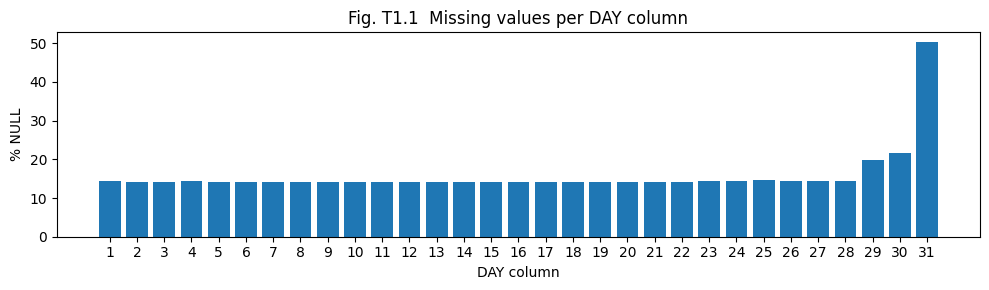

In [ ]:
 # AI: plotting code written with AI assistance
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(10, 3))                          # EXPLAIN: create an empty figure
ax.bar(range(1, 32), [null_pct[c] for c in DAY_COLS])            # EXPLAIN: one bar per DAY column
ax.set_xlabel("DAY column"); ax.set_ylabel("% NULL"); ax.set_xticks(range(1, 32))
ax.set_title("Fig. T1.1  Missing values per DAY column")
plt.tight_layout(); plt.savefig("figures/T1_1_completeness.png", dpi=150); plt.show()

 9. Preprocessing and feature engineering

 REF: Week1_Day02_PySpark_Student_Workbook › Exercise 2.3

 AI: element-join + single stack() reshape, gap-aware lags and the target

In [ ]:
 # REF: Week1_Day02_PySpark_Student_Workbook › Exercise 2.3 (cell-9)
## AI: bronze Parquet cache, single-pass unpivot + pivot (replaces 6 filters + 5 joins), gap-aware lags
## and target written with AI assistance
# ==============================================================================
ELEMS = ["TMAX", "TMIN", "TOBS", "PRCP", "SNOW", "SNWD"]
KEYS  = ["ID", "YEAR", "MONTH"]
LAKE  = os.environ.get("CW_LAKE_DIR", "/content/lakehouse" if IN_COLAB else "./lakehouse")

# Fewer shuffle partitions: the default 200 is far too many for Colab / a laptop (2-4 cores)
spark.conf.set("spark.sql.shuffle.partitions", os.environ.get("CW_SHUFFLE_PARTS", "16"))
spark.conf.set("spark.sql.adaptive.enabled", "true")                            # EXPLAIN: AQE merges small partitions

# Optional for low-memory machines: keep only X% of stations (whole stations, so their time series stay complete)
# e.g. run  os.environ["CW_STATION_SAMPLE_PCT"] = "5"  before this cell while testing
STATION_SAMPLE_PCT = int(os.environ.get("CW_STATION_SAMPLE_PCT", "100"))

# 9.0 BRONZE: save the parsed raw data to Parquet once, so the text files are never re-parsed
BRONZE = f"{LAKE}/bronze_raw"
if not os.path.exists(f"{BRONZE}/_SUCCESS"):
    t0 = time.time()
    raw.filter(F.col("ELEM").isin(ELEMS)).write.mode("overwrite").parquet(BRONZE)   # EXPLAIN: only the 6 elements we use
    TIMINGS["bronze_build_s"] = round(time.time() - t0, 2)
    print(f"bronze written in {TIMINGS['bronze_build_s']} s")
bronze = spark.read.parquet(BRONZE)

base = bronze
if STATION_SAMPLE_PCT < 100:
    base = base.filter(F.crc32("ID") % 100 < STATION_SAMPLE_PCT)                # EXPLAIN: crc32 = repeatable hash
base = base.dropDuplicates(["ID", "YEAR", "MONTH", "ELEM"])                       # 9.1

# 9.2 / 9.3 EXPLAIN: ONE pass over the data instead of six filters and five joins.
#   Step 1: unpivot the 31 DAY columns into rows -> (ID, YEAR, MONTH, ELEM, DAY, VAL)
#   Step 2: drop invalid values (per-element range, 32767 sentinel)
#   Step 3: pivot ELEM back into columns, one row per station-day (single shuffle)
stack_sql = "stack(31, " + ", ".join(f"{i}, `{d}`" for i, d in enumerate(DAY_COLS, start=1)) + ") as (DAY, VAL)"

valid = None
for e in ELEMS:
    lo_, hi_ = VALID_RANGE[e]
    c = (F.col("ELEM") == e) & F.col("VAL").between(lo_, hi_)
    valid = c if valid is None else (valid | c)
valid = valid & (F.col("VAL") != 32767)

days_in_month = F.dayofmonth(F.last_day(F.make_date("YEAR", "MONTH", F.lit(1))))
long = (base.select(*KEYS, "ELEM", F.expr(stack_sql))
            .filter(valid)
            .filter(F.col("DAY") <= days_in_month))                              # 9.4 drop e.g. 31 Feb

daily = (long.groupBy(*KEYS, "DAY")
             .pivot("ELEM", ELEMS)                                               # EXPLAIN: explicit list = no extra job
             .agg(F.first("VAL"))
             .filter(F.col("TMAX").isNotNull())                                  # TMAX is needed for the target
             .withColumn("date", F.make_date("YEAR", "MONTH", "DAY"))
             .withColumn("TMAX", F.col("TMAX") / 10).withColumn("TMIN", F.col("TMIN") / 10)   # 9.5
             .withColumn("TOBS", F.col("TOBS") / 10).withColumn("PRCP", F.col("PRCP") / 10)
             .withColumn("TMIN", F.when(F.col("TMIN") <= F.col("TMAX"), F.col("TMIN"))))  # TMIN above TMAX is an error

# 9.6 / 9.7 features and target, computed per station in date order
w      = Window.partitionBy("ID").orderBy("dnum")                                 # EXPLAIN: per-station, date order
w_7day = Window.partitionBy("ID").orderBy("dnum").rangeBetween(-6, 0)            # EXPLAIN: today + 6 previous days

def lag_exact(col, k):
    # EXPLAIN: value from k days earlier, but only if that row is exactly k calendar days back
    return F.when(F.lag("dnum", k).over(w) == F.col("dnum") - k, F.lag(col, k).over(w))

features = (daily
    .withColumn("dnum", F.datediff("date", F.lit("1970-01-01").cast("date")))   # EXPLAIN: day number
    .withColumn("TMAX_lag1", lag_exact("TMAX", 1))
    .withColumn("TMAX_lag2", lag_exact("TMAX", 2))
    .withColumn("TMAX_roll7", F.avg("TMAX").over(w_7day))
    .withColumn("TMIN_roll7", F.avg("TMIN").over(w_7day))
    .withColumn("DTR", F.col("TMAX") - F.col("TMIN"))
    .withColumn("doy_sin", F.sin(2 * math.pi * F.dayofyear("date") / 365.25))
    .withColumn("doy_cos", F.cos(2 * math.pi * F.dayofyear("date") / 365.25))
    .withColumn("YEAR_f", F.col("YEAR").cast("double"))
    .withColumn("state_code", F.when(F.substring("ID", 1, 3) == "USC", F.substring("ID", 6, 2)).otherwise("OTHER"))
    .withColumn("label_TMAX_next",                                                # TARGET
                F.when(F.lead("dnum", 1).over(w) == F.col("dnum") + 1, F.lead("TMAX", 1).over(w)))
    .filter(F.col("label_TMAX_next").isNotNull())
    .drop("dnum", "DAY"))

t0 = time.time()
(features
    .sortWithinPartitions("YEAR")                                                # EXPLAIN: groups years inside each task, no extra shuffle
    .write.mode("overwrite").partitionBy("YEAR").parquet(f"{LAKE}/silver_features"))
# REF: Workbook › Exercise 4.1 (cell-13) partitionBy(...).parquet(...). Partition key = YEAR (54 values, low cardinality)
TIMINGS["feature_build_s"] = round(time.time() - t0, 2)

silver = spark.read.parquet(f"{LAKE}/silver_features")
N_SILVER = silver.count()
print(f"station-day rows after preprocessing: {N_SILVER:,} | built in {TIMINGS['feature_build_s']} s | "
      f"Parquet size {get_folder_size_mb(f'{LAKE}/silver_features'):,.1f} MB")
silver.select("ID", "date", "TMAX", "TMAX_lag1", "TMAX_roll7", "state_code", "label_TMAX_next").show(5)

NUM_FEATURES = ["TMAX", "TMIN", "TOBS", "PRCP", "SNOW", "SNWD", "TMAX_lag1", "TMAX_lag2",
                "TMAX_roll7", "TMIN_roll7", "DTR", "doy_sin", "doy_cos", "YEAR_f"]
CORR = {c: round(v, 4) for c, v in silver.select([F.corr(c, "label_TMAX_next").alias(c) for c in NUM_FEATURES])
        .collect()[0].asDict().items() if v is not None}                          # EXPLAIN: Pearson correlation
print("Table T1.2  correlation with next-day TMAX:", dict(sorted(CORR.items(), key=lambda kv: -abs(kv[1]))))

station-day rows after preprocessing: 57,191,149 | built in 3083.95 s | Parquet size 773.4 MB
+-----------+----------+----+---------+------------------+----------+---------------+
|         ID|      date|TMAX|TMAX_lag1|        TMAX_roll7|state_code|label_TMAX_next|
+-----------+----------+----+---------+------------------+----------+---------------+
|USC00010655|2008-01-01|15.0|     12.2|12.928571428571429|        01|            6.7|
|USC00010655|2008-01-02| 6.7|     15.0|12.542857142857144|        01|           -1.7|
|USC00010655|2008-01-03|-1.7|      6.7|10.471428571428572|        01|            2.8|
|USC00010655|2008-01-04| 2.8|     -1.7| 9.042857142857143|        01|           10.0|
|USC00010655|2008-01-05|10.0|      2.8|  8.17142857142857|        01|           13.3|
+-----------+----------+----+---------+------------------+----------+---------------+
only showing top 5 rows
Table T1.2  correlation with next-day TMAX: {'TMAX': 0.9335, 'TMAX_roll7': 0.9041, 'TOBS': 0.8838, 'TMAX_lag

10. PySpark Pipeline construction

In [ ]:
import os
# Use a 5% sample of stations to fit the pipeline in a reasonable time on Colab
os.environ["CW_STATION_SAMPLE_PCT"] = "5"

# Re-trigger the subset of silver features quickly
silver_subset = silver.filter(F.crc32("ID") % 100 < 5)
train_df_sampled = silver_subset.filter(F.col("YEAR") <= 2015)
test_df_sampled  = silver_subset.filter(F.col("YEAR") >  2015)

print(f"Sampled Train split: {train_df_sampled.count():,} rows, Sampled Test split: {test_df_sampled.count():,} rows")

from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

NUMERIC_COLS  = NUM_FEATURES
IMPUTED_COLS  = [f"{c}_imputed" for c in NUMERIC_COLS]

# Stage 1: Imputer
imputer = Imputer(
    strategy="median",
    inputCols=NUMERIC_COLS,
    outputCols=IMPUTED_COLS
)

# Stage 2: StringIndexer
indexer = StringIndexer(
    handleInvalid="keep",
    inputCols=["state_code"],
    outputCols=["state_code_indexed"]
)

# Stage 3: OneHotEncoder
encoder = OneHotEncoder(
    inputCols=["state_code_indexed"],
    outputCols=["state_code_vec"]
)

# Stage 4: VectorAssembler
assembler = VectorAssembler(
    inputCols=IMPUTED_COLS + ["state_code_vec"],
    outputCol="raw_features"
)

# Stage 5: StandardScaler
scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withMean=False,
    withStd=True
)

# Complete Pipeline
pipeline = Pipeline(stages=[imputer, indexer, encoder, assembler, scaler])

print("Fitting PySpark Pipeline Model...")
t0 = time.time()
fitted_model = pipeline.fit(train_df_sampled)
TIMINGS["pipeline_fit_s"] = round(time.time() - t0, 2)

# Deliverable Stage List Inspection
stages_list = [type(s).__name__ for s in fitted_model.stages]
print(f"Fitted Pipeline Stages: {stages_list}")
PIPELINE_STAGES = stages_list

# Check the output on 3 rows
prepared = fitted_model.transform(train_df_sampled.limit(3))
prepared.select("ID", "date", "features", "label_TMAX_next").show(3, truncate=70)
print("feature vector length:", prepared.first()["features"].size, "| fit time:", TIMINGS["pipeline_fit_s"], "s")

# Save Fitted Pipeline Model
MODEL_DIR = os.environ.get("CW_MODEL_DIR", "/content/models" if IN_COLAB else "./models")
model_save_path = f"{MODEL_DIR}/task1_pipeline"
fitted_model.write().overwrite().save(model_save_path)
print(f"Fitted Pipeline Model saved to: {model_save_path}")

Sampled Train split: 2,555,512 rows, Sampled Test split: 433,788 rows
Fitting PySpark Pipeline Model...
Fitted Pipeline Stages: ['ImputerModel', 'StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'StandardScalerModel']
+-----------+----------+----------------------------------------------------------------------+---------------+
|         ID|      date|                                                              features|label_TMAX_next|
+-----------+----------+----------------------------------------------------------------------+---------------+
|USC00029359|2008-01-01|(54,[0,1,2,6,7,8,9,10,11,12,13,20],[0.5607894220444805,-0.717168948...|            7.8|
|USC00029359|2008-01-02|(54,[0,1,2,6,7,8,9,10,11,12,13,20],[0.6528593271562608,-0.101139210...|            8.9|
|USC00029359|2008-01-03|(54,[0,1,2,6,7,8,9,10,11,12,13,20],[0.7449292322680413,0.1011392106...|            6.7|
+-----------+----------+----------------------------------------------------------------------+--

 11.EVIDANCE OF EP1

In [ ]:
# ==============================================================================
# EP1 - one cell, in the order required by the answer sheet
## AI: layout written with AI assistance
# ==============================================================================
print("=" * 80)
print(f"7006SCN | {DECLARATION['student_name']} | {DECLARATION['student_email']} | "
      f"Pool ref {DECLARATION['pool_reference']} | {DECLARATION['dataset_name']}")
print("=" * 80)
spark = SparkSession.builder.appName("7006SCN-Task1-GHCN-Regression").getOrCreate()
print(f"[1] SparkSession : Spark {spark.version} | master {spark.sparkContext.master} | "
      f"{spark.sparkContext.defaultParallelism} cores | driver {DRIVER_MEMORY} | shuffle partitions {SHUFFLE_PARTITIONS}")
print("[2] df.printSchema():")
raw.printSchema()
print(f"[3] rows = {raw.count():,} | columns = {len(raw.columns)}")
print(f"[4] file size = {os.path.getsize(CSV_PATH):,} bytes = {os.path.getsize(CSV_PATH) / 1024**3:.2f} GiB")
print(f"[5] partitions after ingestion = {raw.rdd.getNumPartitions()}")
print(f"[6] Fitted Pipeline Stages: {[type(s).__name__ for s in fitted_model.stages]}")

7006SCN | <<YOUR FULL NAME>> | <<YOUR UNIVERSITY E-MAIL>> | Pool ref <<POOL REF>> | climate.csv - GHCN-Daily US weather-station records (1970-2023)
[1] SparkSession : Spark 4.0.4 | master local[*] | 2 cores | driver 6g | shuffle partitions 32
[2] df.printSchema():
root
 |-- ID: string (nullable = true)
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- ELEM: string (nullable = true)
 |-- DAY1: double (nullable = true)
 |-- DAY2: double (nullable = true)
 |-- DAY3: double (nullable = true)
 |-- DAY4: double (nullable = true)
 |-- DAY5: double (nullable = true)
 |-- DAY6: double (nullable = true)
 |-- DAY7: double (nullable = true)
 |-- DAY8: double (nullable = true)
 |-- DAY9: double (nullable = true)
 |-- DAY10: double (nullable = true)
 |-- DAY11: double (nullable = true)
 |-- DAY12: double (nullable = true)
 |-- DAY13: double (nullable = true)
 |-- DAY14: double (nullable = true)
 |-- DAY15: double (nullable = true)
 |-- DAY16: double (nullable = true)
 |

result task1

In [ ]:
# ==============================================================================
# 12. results/task1.json - Pool reference, dataset size, source, licence, pipeline (>=3 stages), cluster config
## AI: JSON structure written with AI assistance; all values come from this run
# ==============================================================================
os.makedirs("results", exist_ok=True)

# Define the missing QUALITY dictionary using values calculated in Section 8
QUALITY = {
    "completeness_pct": {
        "min_day1_28": round(min(null_pct[f'DAY{i}'] for i in range(1, 29)), 2),
        "max_day1_28": round(max(null_pct[f'DAY{i}'] for i in range(1, 29)), 2),
        "day29": round(null_pct['DAY29'], 2),
        "day30": round(null_pct['DAY30'], 2),
        "day31": round(null_pct['DAY31'], 2)
    },
    "uniqueness": {
        "duplicate_rows": dup_rows
    }
}

task1 = {
    "pool_reference": DECLARATION["pool_reference"],
    "student": {k: DECLARATION[k] for k in ("student_name", "student_email", "sid")},
    "dataset": {"name": DECLARATION["dataset_name"], "source_url": DECLARATION["source_url"],
                "original_source": DECLARATION["original_source"], "licence": DECLARATION["licence"],
                "rows": N_ROWS, "columns": N_COLS, "file_size_bytes": FILE_BYTES,
                "file_size_gib": round(FILE_GIB, 3), "partitions_after_ingestion": N_PARTITIONS},
    "big_data_requirements": {"rows_ge_10M": N_ROWS >= 10_000_000, "cols_ge_10": N_COLS >= 10,
                              "size_ge_1GiB": FILE_GIB >= 1, "not_kaggle": True, "pipeline_in_pyspark": True},
    "problem": {"type": "regression", "target": "label_TMAX_next",
                "target_meaning": "next-day maximum temperature at the same station (deg C)",
                "train_years": f"1970-{TRAIN_MAX_YEAR}", "test_years": f"{TRAIN_MAX_YEAR + 1}-2023"},
    "cluster_config": CLUSTER_CONFIG,
    "quality": QUALITY,
    "station_day_rows": N_SILVER,
    "features": NUM_FEATURES + ["state_code (one-hot)"],
    "feature_target_correlation": CORR,
    "pipeline_stages": PIPELINE_STAGES,
    "pipeline_stage_count": len(PIPELINE_STAGES),
    "timings_s": TIMINGS,
}
with open("results/task1.json", "w") as f:
    json.dump(task1, f, indent=2)                                      # EXPLAIN: write the dictionary as JSON
print(json.dumps(task1, indent=2))

{
  "pool_reference": "<<POOL REF>>",
  "student": {
    "student_name": "<<YOUR FULL NAME>>",
    "student_email": "<<YOUR UNIVERSITY E-MAIL>>",
    "sid": "<<YOUR SID>>"
  },
  "dataset": {
    "name": "climate.csv - GHCN-Daily US weather-station records (1970-2023)",
    "source_url": "https://huggingface.co/datasets/CatLikeIceCream/temperature",
    "original_source": "NOAA NCEI Global Historical Climatology Network - Daily (GHCN-Daily)",
    "licence": "None declared on the Hugging Face mirror; original NOAA GHCN-Daily is US-Government public-domain data (citation of Menne et al. 2012 requested)",
    "rows": 17097453,
    "columns": 35,
    "file_size_bytes": 2730667293,
    "file_size_gib": 2.543,
    "partitions_after_ingestion": 21
  },
  "big_data_requirements": {
    "rows_ge_10M": true,
    "cols_ge_10": true,
    "size_ge_1GiB": true,
    "not_kaggle": true,
    "pipeline_in_pyspark": true
  },
  "problem": {
    "type": "regression",
    "target": "label_TMAX_next",
    "